# Peak tracking langmuir fit


In [1]:
import argparse
import json
from dataclasses import asdict, dataclass
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar
from scipy import stats
from stochastic_fano import load_stochastic_fano, sample_spectral_images
from concentration_split import grouped_concentration_split, regression_metrics


In [2]:
PACKAGE = Path.cwd().parent
ROOT = PROJECT = PROJECT_ROOT = PACKAGE / 'work'
SETTINGS = argparse.Namespace(data_dir=PACKAGE / 'work/langmuir_spectral_images_double_ellipse_S843_theta205_D6p52_random10000_logC_m10p5_m8_t7200_dt60_allparam_noise0p05_spectrum0p01', 
                              fano_dir=PACKAGE / 'work/fano_forward_model_double_ellipse_S843_theta205_0to6nm_parameter_noise0p05', 
                              out_dir=PACKAGE / 'work/models/peak_tracking_double_ellipse_S843_theta205_D6p52_random10000_logC_m10p5_m8_t7200_dt60_allparam_noise0p05_spectrum0p01', 
                              figure_dir=PACKAGE / 'work/figures/peak_tracking_double_ellipse_S843_theta205_D6p52_random10000_logC_m10p5_m8_t7200_dt60_allparam_noise0p05_spectrum0p01', 
                              kon=55800.0, koff=1.79e-05, protein_diameter_nm=6.52, thickness_scale_nm=3.413864016900908, calibration_seed=7, wavelength_stride=20, log10_c_min=-10.5, log10_c_max=-8.0)


In [3]:
@dataclass
class PeakCalibration:
    slope_nm_per_nm: float
    intercept_nm: float
    reference_peak_nm: float
    r2: float
    rmse_nm: float

In [4]:
def peak_position(transmission: np.ndarray, wavelength_nm: np.ndarray) -> float:
    idx = int(np.argmin(transmission))
    if idx == 0 or idx == len(transmission) - 1:
        return float(wavelength_nm[idx])
    y0, y1, y2 = (transmission[idx - 1], transmission[idx], transmission[idx + 1])
    denom = y0 - 2.0 * y1 + y2
    if abs(float(denom)) < 1e-12:
        return float(wavelength_nm[idx])
    step = float(wavelength_nm[idx + 1] - wavelength_nm[idx])
    offset = 0.5 * float(y0 - y2) / float(denom)
    offset = float(np.clip(offset, -1.0, 1.0))
    return float(wavelength_nm[idx] + offset * step)


In [5]:
def fit_concentration_log10(time_s: np.ndarray, thickness_nm: np.ndarray, kon: float, koff: float, thickness_scale_nm: float, log10_min: float, log10_max: float) -> float:

    def objective(log10_c: float) -> float:
        prediction = langmuir_thickness(time_s, log10_c, kon, koff, thickness_scale_nm)
        residual = prediction - thickness_nm
        return float(np.mean(residual ** 2))
    result = minimize_scalar(objective, bounds=(log10_min, log10_max), method='bounded', options={'xatol': 1e-06})
    return float(result.x)


In [6]:
def langmuir_thickness(time_s: np.ndarray, log10_c: float, kon: float, koff: float, thickness_scale_nm: float) -> np.ndarray:
    concentration = 10.0 ** log10_c
    rate = kon * concentration + koff
    return thickness_scale_nm * (kon * concentration / rate) * (1.0 - np.exp(-rate * time_s))


In [7]:
def serializable_args(args: argparse.Namespace) -> dict:
    values = vars(args).copy()
    for key, value in values.items():
        if isinstance(value, Path):
            values[key] = str(value)
    return values


## Calculation

Run these cells after the definitions above.

In [8]:
args = SETTINGS
args.out_dir.mkdir(parents=True, exist_ok=True)
args.figure_dir.mkdir(parents=True, exist_ok=True)

images = np.load(args.data_dir / 'spectral_images.npy', mmap_mode='r')
wavelength_nm = np.load(args.data_dir / 'wavelength_nm.npy')
time_s = np.load(args.data_dir / 'time_s.npy')
metadata = pd.read_csv(args.data_dir / 'spectral_image_metadata.csv')
model = load_stochastic_fano(args.fano_dir, args.wavelength_stride)
calibration_spectra = sample_spectral_images(model['thickness_nm'][:, None], model, np.random.default_rng(args.calibration_seed))[:, :, 0]

fano = {'wavelength_nm': model['wavelength_nm'], 'thickness_nm': model['thickness_nm'], 'spectra': calibration_spectra}

peaks = np.array([peak_position(spectrum, fano['wavelength_nm']) for spectrum in fano['spectra']])
thickness = fano['thickness_nm'].astype(np.float64)

slope, intercept = np.polyfit(thickness, peaks, 1)
fitted = slope * thickness + intercept
residual = peaks - fitted

ss_res = float(np.sum(residual ** 2))
ss_tot = float(np.sum((peaks - peaks.mean()) ** 2))

calibration = PeakCalibration(slope_nm_per_nm=float(slope), 
                              intercept_nm=float(intercept), 
                              reference_peak_nm=float(intercept), 
                              r2=float(1.0 - ss_res / ss_tot), 
                              rmse_nm=float(np.sqrt(np.mean(residual ** 2))))

rows = pd.DataFrame({'thicknessNm': thickness, 
                     'noisyPeakWavelengthNm': peaks, 
                     'linearFitPeakWavelengthNm': fitted, 
                     'residualNm': residual})

calibration, calibration_rows = (calibration, rows)
calibration_rows.to_csv(args.out_dir / 'noisy_peak_calibration_points.csv', index=False)
output_dir = args.out_dir

with (output_dir / 'noisy_peak_calibration.json').open('w', encoding='utf-8') as handle:
    json.dump(asdict(calibration), handle, indent=2)

rows = calibration_rows
calibration = calibration

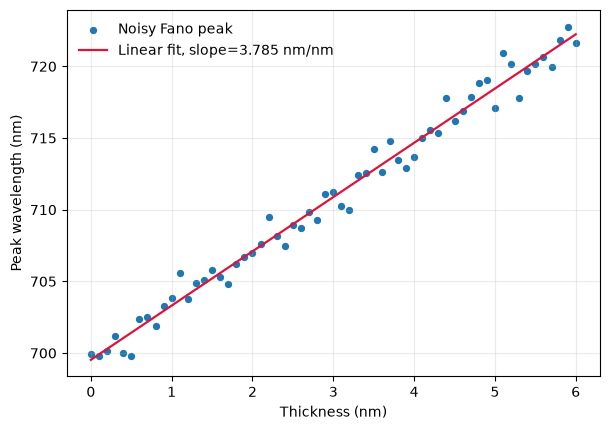

In [9]:
output_path = args.figure_dir / 'noisy_peak_vs_thickness_calibration.svg'

fig, ax = plt.subplots(figsize=(6.2, 4.4))
ax.scatter(rows['thicknessNm'], rows['noisyPeakWavelengthNm'], s=18, label='Noisy Fano peak')
ax.plot(rows['thicknessNm'], rows['linearFitPeakWavelengthNm'], color='crimson', linewidth=1.6, label=f'Linear fit, slope={calibration.slope_nm_per_nm:.3f} nm/nm')
ax.set_xlabel('Thickness (nm)')
ax.set_ylabel('Peak wavelength (nm)')

ax.grid(True, alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
#fig.savefig(output_path)
#plt.close(fig)

In [10]:
n_records = len(metadata)
peak_nm = np.empty((n_records, len(time_s)), dtype=np.float32)
thickness_est = np.empty_like(peak_nm)
pred_log10_c = np.empty(n_records, dtype=np.float64)
thickness_scale_nm = args.thickness_scale_nm
for index in range(n_records):
    image = np.asarray(images[index], dtype=np.float32)
    peak_positions_image = image
    peak_positions_wavelength_nm = wavelength_nm
    peak_trace = np.array([peak_position(peak_positions_image[:, peak_positions_i], peak_positions_wavelength_nm) for peak_positions_i in range(peak_positions_image.shape[1])], dtype=np.float32)
    peak_nm[index] = peak_trace
    delta_peak_nm = peak_trace - peak_trace[0]
    estimated_trace = delta_peak_nm / calibration.slope_nm_per_nm
    thickness_est[index] = estimated_trace
    pred_log10_c[index] = fit_concentration_log10(time_s, estimated_trace, args.kon, args.koff, thickness_scale_nm, args.log10_c_min, args.log10_c_max)
    if (index + 1) % 500 == 0 or index + 1 == n_records:
        print(f'Processed {index + 1}/{n_records} records')

Processed 500/10000 records
Processed 1000/10000 records
Processed 1500/10000 records
Processed 2000/10000 records
Processed 2500/10000 records
Processed 3000/10000 records
Processed 3500/10000 records
Processed 4000/10000 records
Processed 4500/10000 records
Processed 5000/10000 records
Processed 5500/10000 records
Processed 6000/10000 records
Processed 6500/10000 records
Processed 7000/10000 records
Processed 7500/10000 records
Processed 8000/10000 records
Processed 8500/10000 records
Processed 9000/10000 records
Processed 9500/10000 records
Processed 10000/10000 records


In [11]:
truth_log10 = np.log10(metadata['concentrationM'].to_numpy(dtype=np.float64))
metrics = regression_metrics(truth_log10, pred_log10_c)

predictions = pd.DataFrame({'recordId': metadata['recordId'].to_numpy(), 
                            'concentrationM': metadata['concentrationM'].to_numpy(), 
                            'true_log10_concentration': truth_log10, 
                            'pred_log10_concentration': pred_log10_c, 
                            'pred_concentrationM': np.power(10.0, pred_log10_c), 
                            'final_peak_nm': peak_nm[:, -1], 
                            'final_estimated_thickness_nm': thickness_est[:, -1]})
predictions.to_csv(args.out_dir / 'peak_tracking_langmuir_predictions.csv', index=False)

split = grouped_concentration_split(metadata, argparse.Namespace(split_seed=7, test_fraction=0.15, val_fraction=0.15))

predictions.iloc[split.test].to_csv(args.out_dir / 'test_predictions.csv', index=False)

pd.DataFrame([metrics]).to_csv(args.out_dir / 'peak_tracking_langmuir_metrics.csv', index=False)

np.save(args.out_dir / 'peak_positions_nm.npy', peak_nm)
np.save(args.out_dir / 'estimated_thickness_traces_nm.npy', thickness_est)

with (args.out_dir / 'experiment_summary.json').open('w', encoding='utf-8') as handle:
    json.dump({'args': serializable_args(args), 'data_shape': list(images.shape), 'target': 'log10_concentrationM', 'calibration': asdict(calibration), 'langmuir_model': {'kon_Minv_sinv': args.kon, 'koff_sinv': args.koff, 'thickness_scale_nm': thickness_scale_nm, 'equation': 'thickness(t)=Tmax*(kon*C)/(kon*C+koff)*(1-exp(-(kon*C+koff)*t))'}, 'metrics': metrics}, handle, indent=2)


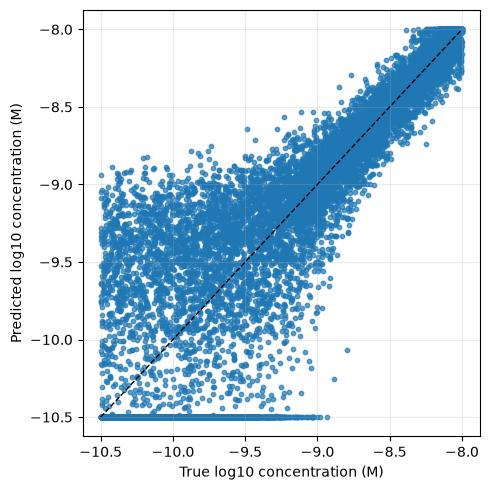

In [12]:
y_true = truth_log10
y_pred = pred_log10_c
output_path = args.figure_dir / 'prediction_vs_ground_truth.svg'

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_true, y_pred, s=10, alpha=0.7)
lims = [min(float(y_true.min()), float(y_pred.min())), max(float(y_true.max()), float(y_pred.max()))]
ax.plot(lims, lims, 'k--', linewidth=1)
ax.set_xlabel('True log10 concentration (M)')
ax.set_ylabel('Predicted log10 concentration (M)')
ax.grid(True, alpha=0.25)
fig.tight_layout()
#fig.savefig(output_path)
#plt.close(fig)

{
  "rmse_log10_concentration": 0.4308987454254021,
  "mae_log10_concentration": 0.3040139712023023,
  "r2_log10_concentration": 0.6416482650404136,
  "pearson_corr": 0.838035856609731,
  "spearman_corr": 0.8694476667910577,
  "median_fold_error": 1.5265215496540177,
  "p90_fold_error": 6.1283025890048455
}


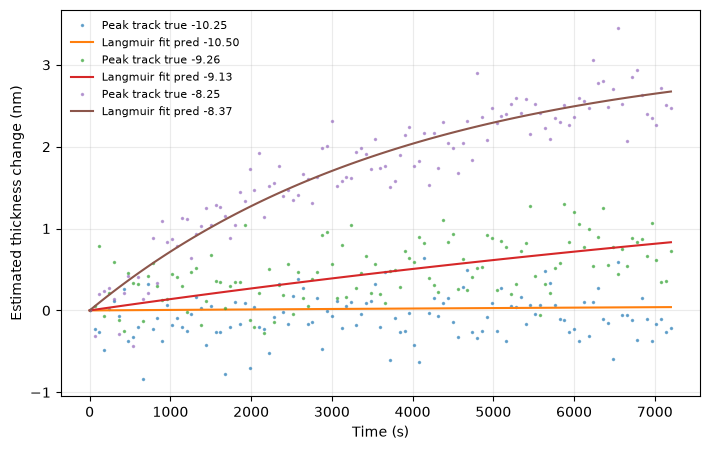

In [13]:
output_path = args.figure_dir / 'example_peak_tracking_thickness_traces.svg'
true_log10 = np.log10(metadata['concentrationM'].to_numpy(dtype=np.float64))
targets = np.quantile(true_log10, [0.1, 0.5, 0.9])
indices = [int(np.argmin(np.abs(true_log10 - target))) for target in targets]
thickness_scale_nm = args.thickness_scale_nm

fig, ax = plt.subplots(figsize=(7.2, 4.6))

for index in indices:
    ax.plot(time_s, thickness_est[index], '.', markersize=3, alpha=0.55, label=f'Peak track true {true_log10[index]:.2f}')
    ax.plot(time_s, langmuir_thickness(time_s, pred_log10_c[index], args.kon, args.koff, thickness_scale_nm), linewidth=1.5, label=f'Langmuir fit pred {pred_log10_c[index]:.2f}')

ax.set_xlabel('Time (s)')
ax.set_ylabel('Estimated thickness change (nm)')
ax.grid(True, alpha=0.25)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
#fig.savefig(output_path)
#plt.close(fig)

print(json.dumps(metrics, indent=2))
